<a href="https://colab.research.google.com/github/yaqoob-sadikeen/AML-Assignment/blob/main/CB016644_AML_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HomeVision: Indoor Scene Recognition for Smart Homes
**COMP50056 Advanced Machine Learning, Assignment 01 (Model Training)**
Student: Yaqoob Sadikeen | Dataset: MIT Indoor Scenes (Kaggle)

This notebook builds an indoor scene recognition system for SmartSense AI's HomeVision product. Two deep learning models are trained and compared: a custom CNN trained from scratch, and MobileNetV2 using transfer learning and fine-tuning.

Contents:
1. Setup and configuration
2. Data loading and cleaning
3. Exploratory data analysis
4. Preprocessing
5. Callbacks and helper functions
6. Model 1: Custom CNN
7. Hyperparameter tuning for MobileNetV2
8. Model 2: MobileNetV2
9. Evaluation on the test set
10. Model comparison
11. Error analysis and Grad-CAM
12. Applications, privacy and limitations
13. Implementation report

Runtime: Colab with a T4 GPU (Runtime > Change runtime type). A full run takes roughly 60 to 90 minutes, most of which is the tuning experiments.

### AI Use statement
Generative AI (Claude) was used to help structure the notebook and draft parts of the code. All experiments were run by me, and the results, design choices and interpretations were defined and are understood by me.

## 1. Setup and configuration
This cell imports the libraries used in the project. TensorFlow/Keras is used to build and train the models, NumPy and Pandas for handling data, Matplotlib and Seaborn for plots, and Scikit-learn for splitting the data and calculating the evaluation metrics. A random seed is set so the results can be reproduced.

In [ ]:
# IMPORTING LIBRARIES
import os
import time
import json
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)   # sets the python, numpy and tensorflow seeds

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Class selection
Five classes were chosen from the 67 in the dataset. Three are home settings (bedroom, kitchen, livingroom) and two are building or public settings (bar, airport_inside), since HomeVision is aimed at both smart homes and smart buildings.

Some of the classes look quite similar. Kitchens and bars both have counters, stools and shelving, and bedrooms and living rooms share soft furnishings and lamps. This was done on purpose, because "visually similar room categories" is one of the problems listed in the brief.

In [ ]:
# CONFIGURATION
CLASSES = ["airport_inside", "bar", "bedroom", "kitchen", "livingroom"]
NUM_CLASSES = len(CLASSES)

IMG_SIZE = 224      # input size MobileNetV2 was trained on
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Epochs
CNN_EXP_EPOCHS = 8      # short runs for the CNN experiments
TL_EXP_EPOCHS = 6       # short runs for the MobileNetV2 experiments
CNN_EPOCHS = 40         # final CNN training (early stopping usually ends it sooner)
HEAD_EPOCHS = 12        # MobileNetV2 phase 1
FINETUNE_EPOCHS = 15    # MobileNetV2 phase 2

# Everything is saved inside the "Assignment" folder
OUT_DIR = Path("Assignment")
FIG_DIR = OUT_DIR / "figures"
MODEL_DIR = OUT_DIR / "models"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Classes:", CLASSES)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Classes: ['airport_inside', 'bar', 'bedroom', 'kitchen', 'livingroom']
Image size: 224
Batch size: 32


## 2. Data loading and cleaning
### 2.1 Download the dataset
This cell downloads the MIT Indoor Scenes dataset (Quattoni and Torralba, 2009) from Kaggle and searches the download for the folder that holds the five class folders. Annotation folders are skipped.

In [ ]:
# DOWNLOAD DATASET
import kagglehub

dataset_root = Path(kagglehub.dataset_download("itsahmad/indoor-scenes-cvpr-2019"))

IMAGES_DIR = None
for dirpath, dirnames, filenames in os.walk(dataset_root):
    if "annotation" in dirpath.lower():
        continue
    if all(cls in dirnames for cls in CLASSES):
        IMAGES_DIR = Path(dirpath)
        break

if IMAGES_DIR is None:
    raise FileNotFoundError("Could not find the class folders.")

print("Images folder:", IMAGES_DIR)
for cls in CLASSES:
    print(cls, ":", (IMAGES_DIR / cls).exists())

Using Colab cache for faster access to the 'indoor-scenes-cvpr-2019' dataset.
Images folder: /kaggle/input/indoor-scenes-cvpr-2019/indoorCVPR_09/Images
airport_inside : True
bar : True
bedroom : True
kitchen : True
livingroom : True


### 2.2 Load, clean, resize and encode
Each image is checked before it is used:
- Files that cannot be opened are skipped.
- Exact duplicates are removed, so the same image cannot appear in both the training and test sets.
- Every image is converted to RGB, because some files are greyscale or use other colour modes.

All images are resized to 224×224 and kept in memory, which makes training faster. The class names are label-encoded as integers from 0 to 4. One-hot encoding is not needed because the models use sparse categorical cross-entropy, which works directly with integer labels.

In [ ]:
# LOAD AND CLEAN IMAGES
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

# Label encoding: class name -> integer
class_to_index = {}
for index, class_name in enumerate(CLASSES):
    class_to_index[class_name] = index
print("Label encoding:", class_to_index)


def load_images(images_dir, classes, size):
    images = []
    labels = []
    rejected = []
    seen_hashes = set()

    for class_name in classes:
        for path in sorted((images_dir / class_name).iterdir()):

            # 1. skip files that are not images
            if path.suffix.lower() not in VALID_EXT:
                rejected.append((path.name, class_name, "not an image"))
                continue

            # 2. skip exact duplicates
            file_hash = hashlib.md5(path.read_bytes()).hexdigest()
            if file_hash in seen_hashes:
                rejected.append((path.name, class_name, "duplicate"))
                continue

            # 3. open, convert to RGB and resize (skip broken files)
            try:
                with Image.open(path) as img:
                    img = img.convert("RGB").resize((size, size))
                    image_array = np.asarray(img, dtype=np.uint8)
            except Exception:
                rejected.append((path.name, class_name, "unreadable"))
                continue

            seen_hashes.add(file_hash)
            images.append(image_array)
            labels.append(class_to_index[class_name])

    rejected_df = pd.DataFrame(rejected, columns=["file", "class", "reason"])
    return np.array(images), np.array(labels), rejected_df


start = time.time()
X_all, y_all, rejected = load_images(IMAGES_DIR, CLASSES, IMG_SIZE)

print(f"Loaded {len(X_all)} images in {time.time() - start:.0f} seconds")
print("Array shape:", X_all.shape)
print("Rejected files:", len(rejected))
display(rejected["reason"].value_counts())

Label encoding: {'airport_inside': 0, 'bar': 1, 'bedroom': 2, 'kitchen': 3, 'livingroom': 4}
Loaded 3298 images in 59 seconds
Array shape: (3298, 224, 224, 3)
Rejected files: 16


,count
reason,
duplicate,16


## 3. Exploratory data analysis
This chart shows the number of images in each class after cleaning. It is used to check whether any class is much larger than the others, which could bias the models towards that class.

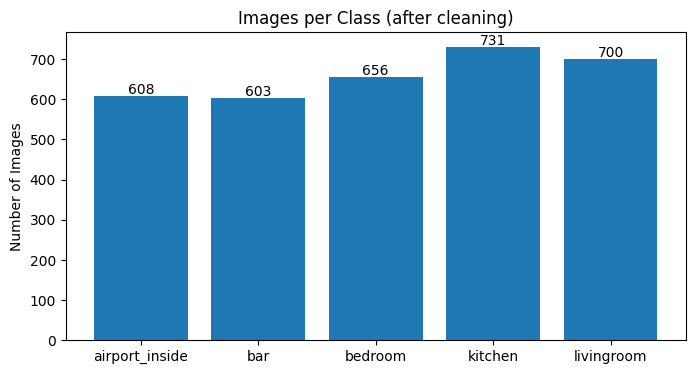

Imbalance ratio (largest / smallest): 1.21


In [ ]:
# CLASS DISTRIBUTION
counts = pd.Series(np.bincount(y_all), index=CLASSES)

plt.figure(figsize=(8, 4))
plt.bar(counts.index, counts.values)
for i, value in enumerate(counts.values):
    plt.text(i, value + 5, str(value), ha="center")
plt.title("Images per Class (after cleaning)")
plt.ylabel("Number of Images")
plt.savefig(FIG_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Imbalance ratio (largest / smallest): {counts.max() / counts.min():.2f}")

The classes are fairly close in size, so no resampling or class weighting is used. Macro F1 is still used as the main metric later on so that every class counts equally.

The cell below shows some example images from each class. It gives an idea of how much the lighting, clutter and camera angle vary within the same room type.

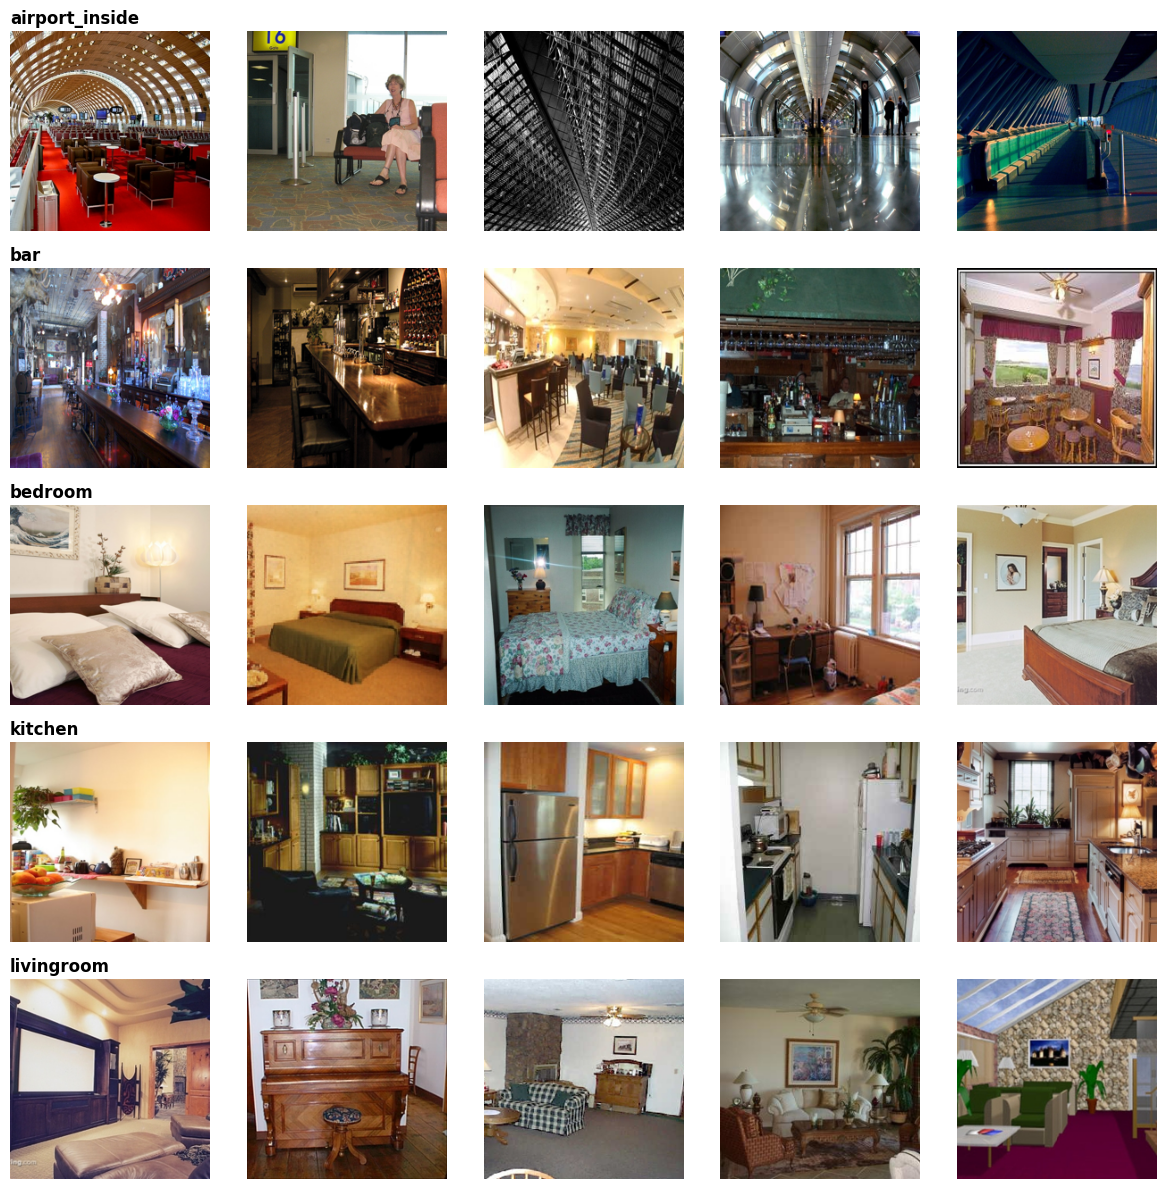

In [ ]:
# SAMPLE IMAGES
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(12, 12))

for row in range(NUM_CLASSES):
    class_indexes = np.where(y_all == row)[0]
    picks = rng.choice(class_indexes, 5, replace=False)
    for col in range(5):
        axes[row, col].imshow(X_all[picks[col]])
        axes[row, col].axis("off")
    axes[row, 0].set_title(CLASSES[row], loc="left", fontweight="bold")

plt.tight_layout()
plt.savefig(FIG_DIR / "sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Preprocessing
### 4.1 Train, validation and test split
The data is split into 70% training, 15% validation and 15% testing. A stratified split is used so that each class has the same proportion in all three sets. The training set is used to learn the weights, the validation set is used for early stopping and choosing hyperparameters, and the test set is only used once at the end to report the final results.

In [ ]:
# TRAIN / VALIDATION / TEST SPLIT
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all,
    test_size=0.30,
    stratify=y_all,
    random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print(f"Training images:   {len(X_train)} ({len(X_train) / len(X_all) * 100:.1f}%)")
print(f"Validation images: {len(X_val)} ({len(X_val) / len(X_all) * 100:.1f}%)")
print(f"Testing images:    {len(X_test)} ({len(X_test) / len(X_all) * 100:.1f}%)")

split_table = pd.DataFrame({
    "Train": np.bincount(y_train),
    "Validation": np.bincount(y_val),
    "Test": np.bincount(y_test)
}, index=CLASSES)
display(split_table)

Training images:   2308 (70.0%)
Validation images: 495 (15.0%)
Testing images:    495 (15.0%)


,Train,Validation,Test
airport_inside,425,91,92
bar,422,91,90
bedroom,459,98,99
kitchen,512,110,109
livingroom,490,105,105


### 4.2 Data augmentation
Augmentation creates slightly changed copies of the training images, so the models see more variety and are less likely to overfit (Shorten and Khoshgoftaar, 2019). Each choice relates to a problem described in the brief:

| Augmentation | Problem from the brief |
|---|---|
| Horizontal flip | different furniture arrangements |
| Small rotation, zoom and shift | different camera angles and positions |
| Brightness and contrast | different lighting conditions |

Vertical flips were not used because rooms are never upside down. Colour changes were also left out, because colour is a useful clue (for example, the warm lighting in a bar compared with a bright kitchen). Augmentation is only applied to the training set, and the validation and test images are left unchanged. Section 6.4 tests whether augmentation actually helps.

In [ ]:
# DATA AUGMENTATION
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05, fill_mode="reflect"),
    tf.keras.layers.RandomZoom(0.15, fill_mode="reflect"),
    tf.keras.layers.RandomTranslation(0.10, 0.10, fill_mode="reflect"),
    tf.keras.layers.RandomBrightness(0.20, value_range=(0, 255)),
    tf.keras.layers.RandomContrast(0.20)
])


def to_float(images, labels):
    return tf.cast(images, tf.float32), labels


def augment_batch(images, labels):
    images = data_augmentation(images, training=True)
    images = tf.clip_by_value(images, 0, 255)   # keep pixel values in the 0-255 range
    return images, labels


def make_dataset(X, y, training=False, use_augmentation=True, batch_size=BATCH_SIZE):
    dataset = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        dataset = dataset.shuffle(len(X), seed=SEED)
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(to_float, num_parallel_calls=AUTOTUNE)
    if training and use_augmentation:
        dataset = dataset.map(augment_batch, num_parallel_calls=AUTOTUNE)
    return dataset.prefetch(AUTOTUNE)


train_ds = make_dataset(X_train, y_train, training=True)
train_ds_no_aug = make_dataset(X_train, y_train, training=True, use_augmentation=False)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

print("TensorFlow datasets created.")

TensorFlow datasets created.


This cell shows one training image next to seven augmented versions of it. It is a visual check that the changes look realistic and that the room is still recognisable.

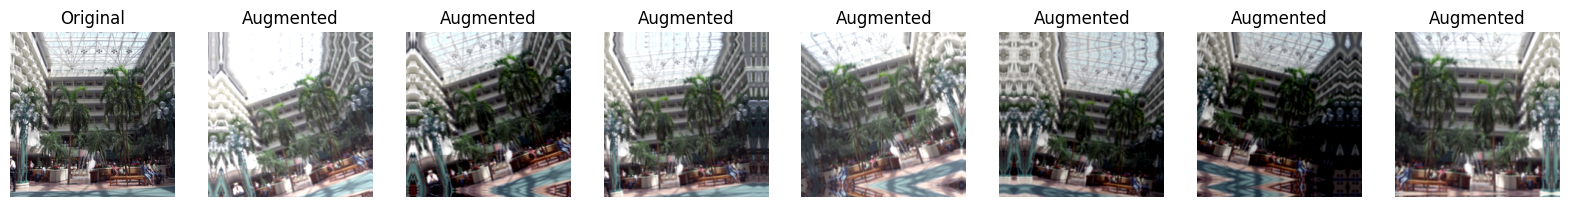

In [ ]:
# VISUALISE AUGMENTATION
sample = tf.cast(X_train[:1], tf.float32)

plt.figure(figsize=(20, 3))
plt.subplot(1, 8, 1)
plt.imshow(X_train[0])
plt.title("Original")
plt.axis("off")

for i in range(2, 9):
    augmented, _ = augment_batch(sample, None)
    plt.subplot(1, 8, i)
    plt.imshow(augmented[0].numpy().astype("uint8"))
    plt.title("Augmented")
    plt.axis("off")

plt.savefig(FIG_DIR / "augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3 Normalisation
The images are kept in the 0 to 255 range, and each model scales them in its first layer. The custom CNN rescales them to 0 to 1, which keeps training stable. MobileNetV2 rescales them to -1 to 1, because that is the range its ImageNet weights were trained with, and using a different range would make the pretrained features much less useful. Doing this inside the model also means the saved model can take raw camera images directly.

## 5. Callbacks and helper functions
### 5.1 Callbacks
EarlyStopping stops training once the validation loss stops improving and restores the weights from the best epoch. ReduceLROnPlateau halves the learning rate when the validation loss levels off.

Three sets of callbacks are used:
- `make_callbacks()` for the final training runs.
- `make_experiment_callbacks()` for the short tuning experiments. Only early stopping is used here, so the learning rate being tested is not changed during the run.
- `make_fine_tune_callbacks()` for fine-tuning, with a lower minimum learning rate because fine-tuning already starts with a very small one.

The callbacks are created by functions so that every training run gets new callback objects. In an earlier run of this notebook, the same EarlyStopping object was reused across runs, and in the Keras version on Colab it kept the best validation loss from the previous run. Later runs then stopped after only a few epochs because they could not beat another model's score. Creating fresh callbacks for each run fixes this and keeps the comparisons fair.

In [ ]:
# CALLBACKS
# Each function returns NEW callback objects, so every training run starts fresh.

def make_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6
        )
    ]


def make_experiment_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]


def make_fine_tune_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-7
        )
    ]


print("Callback functions created.")

Callback functions created.


### 5.2 Helper functions
These functions are reused throughout the notebook so that every model and experiment is handled in the same way:
- `plot_history` plots training and validation accuracy and loss.
- `fit_and_score` trains a model for a short experiment and returns its best validation accuracy, best validation loss and training time.
- `pick_best` shows the results of an experiment as a table and a graph, and picks the value with the highest validation accuracy (the lower validation loss breaks any ties). The test set is never used for this.

In [ ]:
# HELPER FUNCTIONS
histories = {}        # training history of each final model
train_times = {}      # training time of each final model (seconds)
trained_models = {}   # the final models
results = {}          # test results of each model
BEST = {}             # selected hyperparameters
tuning_tables = []    # all experiment tables, combined in section 7.6


def plot_history(history, title, finetune_start=None):
    plt.figure(figsize=(13, 4))
    for i, metric in enumerate(["accuracy", "loss"]):
        plt.subplot(1, 2, i + 1)
        plt.plot(history[metric], label="Training")
        plt.plot(history["val_" + metric], label="Validation")
        if finetune_start is not None:
            plt.axvline(finetune_start - 0.5, linestyle="--", color="grey", label="Fine-tuning starts")
        plt.title(f"{title} {metric.capitalize()}")
        plt.xlabel("Epoch")
        plt.legend()
    plt.savefig(FIG_DIR / f"curves_{title}.png", dpi=150, bbox_inches="tight")
    plt.show()


def fit_and_score(model, train_data, val_data, epochs):
    start = time.time()
    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=epochs,
        callbacks=make_experiment_callbacks(),
        verbose=1
    )
    return {
        "Best Validation Accuracy": max(history.history["val_accuracy"]),
        "Best Validation Loss": min(history.history["val_loss"]),
        "Training Time (min)": (time.time() - start) / 60
    }


def pick_best(experiment_results, param):
    df = pd.DataFrame(experiment_results)

    # highest validation accuracy first, lower validation loss breaks ties
    ranked = df.sort_values(["Best Validation Accuracy", "Best Validation Loss"], ascending=[False, True])
    best_value = ranked[param].tolist()[0]
    df["Selected"] = df[param] == best_value
    display(df)

    plt.figure(figsize=(7, 4))
    plt.plot(df[param].astype(str), df["Best Validation Accuracy"], marker="o")
    plt.title(f"{param} vs Validation Accuracy")
    plt.xlabel(param)
    plt.ylabel("Best Validation Accuracy")
    plt.savefig(FIG_DIR / f"experiment_{param}.png", dpi=150, bbox_inches="tight")
    plt.show()

    df["Hyperparameter"] = param
    tuning_tables.append(df.rename(columns={param: "Value"}))
    print(f"Selected {param} = {best_value}")
    return best_value

## 6. Model 1: Custom CNN
The custom CNN is trained from scratch and acts as a baseline. It shows how well a model can do without any pretrained knowledge, which makes it possible to measure how much transfer learning actually adds.

Design choices:
- Four convolutional blocks with 32, 64, 128 and 256 filters. The early blocks pick up simple features like edges and textures, and the deeper blocks combine them into larger patterns such as furniture parts.
- Two 3×3 convolutions in each block. Stacking small filters covers the same area as one larger filter but uses fewer parameters.
- ReLU activations and batch normalisation after each convolution to keep training stable.
- Max pooling to halve the image size after each block.
- Global average pooling instead of flattening, which greatly reduces the number of parameters.
- A dense layer with L2 regularisation and dropout to reduce overfitting, since the dataset is small.
- A softmax output layer that gives a probability for each of the five rooms.

The Adam optimiser is used for every model. It adjusts the step size for each weight automatically, which makes it a reliable choice for CNNs without much manual adjustment.

In [ ]:
# MODEL 1 - CUSTOM CNN
def build_custom_cnn(learning_rate=0.001, dropout_rate=0.5):

    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    model.add(tf.keras.layers.Rescaling(1.0 / 255))      # 0-255 -> 0-1

    # 4 convolutional blocks
    for filters in [32, 64, 128, 256]:
        model.add(tf.keras.layers.Conv2D(filters, (3, 3), padding="same", activation="relu"))
        model.add(tf.keras.layers.BatchNormalization())
        model.add(tf.keras.layers.Conv2D(filters, (3, 3), padding="same", activation="relu"))
        model.add(tf.keras.layers.BatchNormalization())
        model.add(tf.keras.layers.MaxPooling2D())

    # Classification head
    model.add(tf.keras.layers.GlobalAveragePooling2D())
    model.add(tf.keras.layers.Dense(128, activation="relu",
                                    kernel_regularizer=tf.keras.regularizers.l2(1e-4)))
    model.add(tf.keras.layers.Dropout(dropout_rate))
    model.add(tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


custom_cnn = build_custom_cnn()
custom_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             

 Total params: 1,209,637 (4.61 MB)

 Trainable params: 1,207,717 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

### 6.1 Learning rate experiment
Models trained from scratch are sensitive to the learning rate. If it is too high, the weights jump around and never settle, and if it is too low, the model learns too slowly. Three values are compared over a few epochs, with dropout kept at 0.5.


Testing learning rate: 0.003
Epoch 1/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 85s 718ms/step - accuracy: 0.3037 - loss: 1.7440 - val_accuracy: 0.1980 - val_loss: 5.5020
Epoch 2/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 507ms/step - accuracy: 0.3635 - loss: 1.4451 - val_accuracy: 0.2525 - val_loss: 2.0978
Epoch 3/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 41s 511ms/step - accuracy: 0.4003 - loss: 1.4036 - val_accuracy: 0.2606 - val_loss: 1.7922
Epoch 4/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 519ms/step - accuracy: 0.4185 - loss: 1.3585 - val_accuracy: 0.2788 - val_loss: 1.7713
Epoch 5/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 40s 505ms/step - accuracy: 0.4281 - loss: 1.3212 - val_accuracy: 0.4101 - val_loss: 1.6841
Epoch 6/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 513ms/step - accuracy: 0.4393 - loss: 1.3033 - val_accuracy: 0.4081 - val_loss: 1.3144
Epoch 7/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 513ms/step - accuracy: 0.4389 - loss: 1.2938 - val_accuracy: 0.4101 - val_loss: 1.3055
Epoch 8/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 515ms/step - accuracy: 0.4701 - l

,Best Validation Accuracy,Best Validation Loss,Training Time (min),cnn_lr,Selected
0,0.410101,1.305488,5.949568,0.0030,False
1,0.416162,1.459114,5.520813,0.0010,True
2,0.218182,2.011792,2.949377,0.0003,False


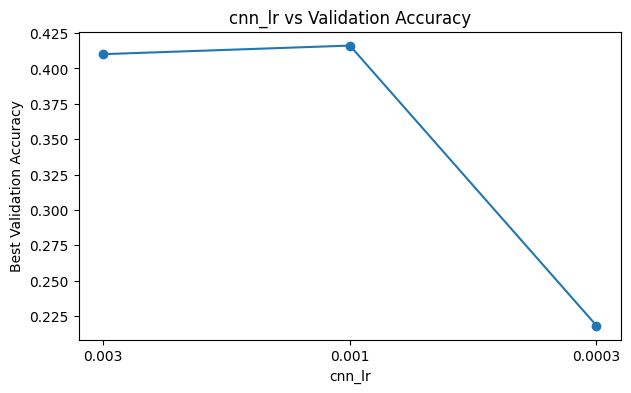

Selected cnn_lr = 0.001


In [ ]:
# EXPERIMENT 1 - CNN LEARNING RATE
cnn_learning_rates = [0.003, 0.001, 0.0003]
cnn_lr_results = []

for lr in cnn_learning_rates:
    print("\n" + "=" * 60)
    print(f"Testing learning rate: {lr}")
    print("=" * 60)

    tf.keras.utils.set_random_seed(SEED)
    model = build_custom_cnn(learning_rate=lr, dropout_rate=0.5)
    scores = fit_and_score(model, train_ds, val_ds, CNN_EXP_EPOCHS)
    scores["cnn_lr"] = lr
    cnn_lr_results.append(scores)

BEST["cnn_lr"] = pick_best(cnn_lr_results, "cnn_lr")

### 6.2 Dropout experiment
Dropout randomly switches off some neurons during training so the model cannot rely too much on any one feature. Too little dropout can lead to overfitting, and too much can stop the model from learning enough. The selected learning rate is used.


Testing dropout: 0.2
Epoch 1/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 58s 620ms/step - accuracy: 0.3674 - loss: 1.4672 - val_accuracy: 0.1980 - val_loss: 2.8279
Epoch 2/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 67s 503ms/step - accuracy: 0.4393 - loss: 1.3355 - val_accuracy: 0.1980 - val_loss: 2.5627
Epoch 3/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 497ms/step - accuracy: 0.4588 - loss: 1.2848 - val_accuracy: 0.2222 - val_loss: 3.0177
Epoch 4/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 511ms/step - accuracy: 0.4866 - loss: 1.2326 - val_accuracy: 0.1717 - val_loss: 3.3231
Epoch 5/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 510ms/step - accuracy: 0.4922 - loss: 1.1997 - val_accuracy: 0.1980 - val_loss: 3.2793

Testing dropout: 0.3
Epoch 1/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 57s 619ms/step - accuracy: 0.3912 - loss: 1.4822 - val_accuracy: 0.2222 - val_loss: 3.3301
Epoch 2/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 67s 514ms/step - accuracy: 0.4263 - loss: 1.3428 - val_accuracy: 0.2222 - val_loss: 3.1200
Epoch 3/8
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 508ms/step - accura

,Best Validation Accuracy,Best Validation Loss,Training Time (min),cnn_dropout,Selected
0,0.222222,2.562660,3.959414,0.2,False
1,0.488889,1.225190,5.909749,0.3,True
2,0.222222,2.719297,2.917293,0.5,False


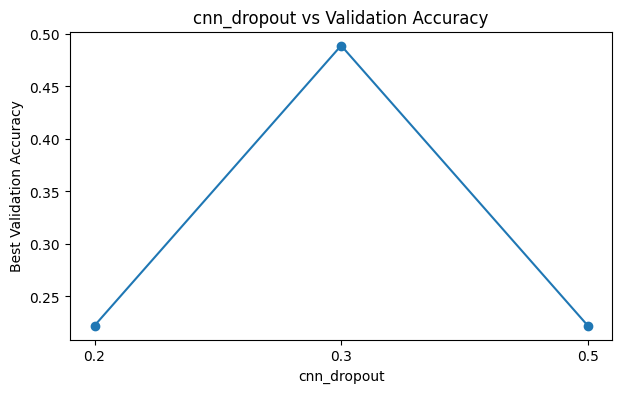

Selected cnn_dropout = 0.3


In [ ]:
# EXPERIMENT 2 - CNN DROPOUT
cnn_dropout_rates = [0.2, 0.3, 0.5]
cnn_dropout_results = []

for dropout in cnn_dropout_rates:
    print("\n" + "=" * 60)
    print(f"Testing dropout: {dropout}")
    print("=" * 60)

    tf.keras.utils.set_random_seed(SEED)
    model = build_custom_cnn(learning_rate=BEST["cnn_lr"], dropout_rate=dropout)
    scores = fit_and_score(model, train_ds, val_ds, CNN_EXP_EPOCHS)
    scores["cnn_dropout"] = dropout
    cnn_dropout_results.append(scores)

BEST["cnn_dropout"] = pick_best(cnn_dropout_results, "cnn_dropout")

### 6.3 Final Custom CNN training
The CNN is now trained with the selected learning rate and dropout. The maximum is set to 40 epochs, but early stopping normally ends training sooner, once the validation loss stops improving. This avoids having to guess the exact number of epochs in advance.

Epoch 1/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 57s 618ms/step - accuracy: 0.3648 - loss: 1.5064 - val_accuracy: 0.1980 - val_loss: 5.4896 - learning_rate: 0.0010
Epoch 2/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 518ms/step - accuracy: 0.4133 - loss: 1.3658 - val_accuracy: 0.1980 - val_loss: 3.2818 - learning_rate: 0.0010
Epoch 3/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 518ms/step - accuracy: 0.4532 - loss: 1.2865 - val_accuracy: 0.1980 - val_loss: 3.1441 - learning_rate: 0.0010
Epoch 4/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 514ms/step - accuracy: 0.4753 - loss: 1.2505 - val_accuracy: 0.1980 - val_loss: 3.5430 - learning_rate: 0.0010
Epoch 5/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 41s 514ms/step - accuracy: 0.5269 - loss: 1.1631 - val_accuracy: 0.2222 - val_loss: 2.9087 - learning_rate: 0.0010
Epoch 6/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 39s 520ms/step - accuracy: 0.5416 - loss: 1.1337 - val_accuracy: 0.3475 - val_loss: 1.7591 - learning_rate: 0.0010
Epoch 7/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 38s 518ms/step - accuracy: 0.5472 - loss: 1.

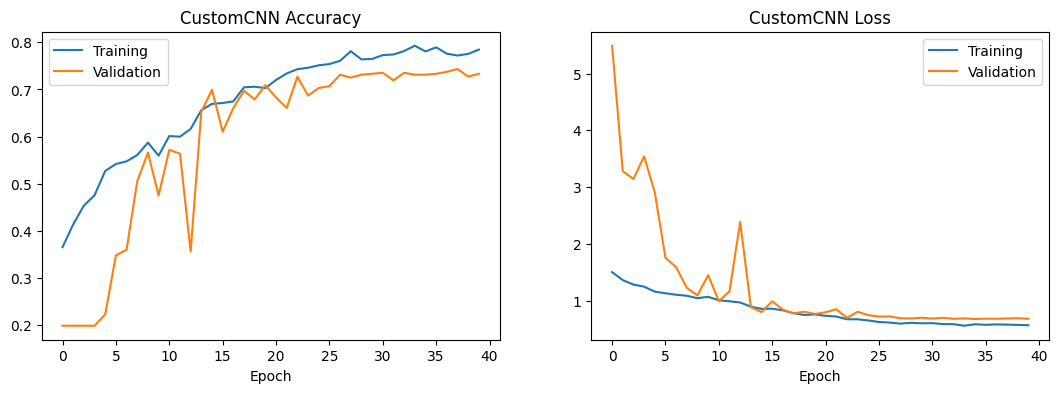

In [ ]:
# TRAIN CUSTOM CNN
tf.keras.utils.set_random_seed(SEED)
custom_cnn = build_custom_cnn(learning_rate=BEST["cnn_lr"], dropout_rate=BEST["cnn_dropout"])

start_time = time.time()
history_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CNN_EPOCHS,
    callbacks=make_callbacks()
)
cnn_training_time = time.time() - start_time
print(f"\nCustom CNN training time: {cnn_training_time / 60:.2f} minutes")

custom_cnn.save(MODEL_DIR / "CustomCNN.keras")
histories["CustomCNN"] = history_cnn.history
train_times["CustomCNN"] = cnn_training_time
trained_models["CustomCNN"] = custom_cnn

plot_history(history_cnn.history, "CustomCNN")

### 6.4 Does augmentation help?
To check whether augmentation is actually worth using, the same CNN is trained again with exactly the same settings but without augmentation. The two runs are compared on their best validation accuracy and on the gap between training and validation accuracy. A larger gap means the model is overfitting more.

Epoch 1/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 36s 355ms/step - accuracy: 0.4125 - loss: 1.4092 - val_accuracy: 0.1980 - val_loss: 3.2031 - learning_rate: 0.0010
Epoch 2/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 18s 241ms/step - accuracy: 0.4697 - loss: 1.2601 - val_accuracy: 0.1980 - val_loss: 3.2053 - learning_rate: 0.0010
Epoch 3/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 17s 236ms/step - accuracy: 0.5030 - loss: 1.1794 - val_accuracy: 0.2424 - val_loss: 3.7191 - learning_rate: 0.0010
Epoch 4/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 16s 225ms/step - accuracy: 0.5568 - loss: 1.0670 - val_accuracy: 0.1980 - val_loss: 3.4006 - learning_rate: 5.0000e-04
Epoch 5/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 16s 224ms/step - accuracy: 0.5940 - loss: 0.9842 - val_accuracy: 0.1980 - val_loss: 3.8812 - learning_rate: 5.0000e-04
Epoch 6/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 17s 229ms/step - accuracy: 0.6386 - loss: 0.9058 - val_accuracy: 0.2162 - val_loss: 3.2534 - learning_rate: 2.5000e-04


,Configuration,Best Train Accuracy,Best Validation Accuracy,Epochs Run,Train - Validation Gap
0,With Augmentation,0.792894,0.743434,40,0.049460
1,Without Augmentation,0.638648,0.242424,6,0.396224


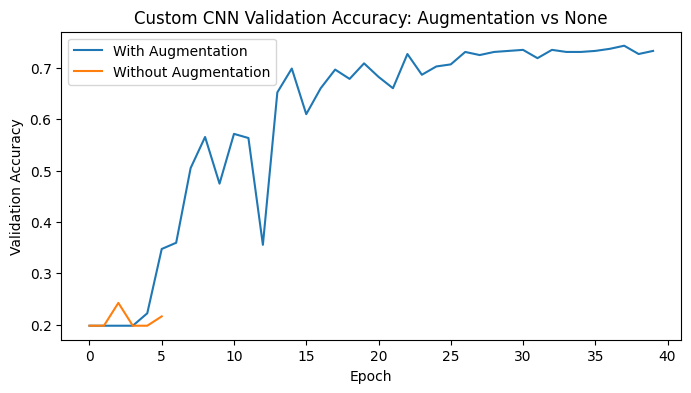

In [ ]:
# EXPERIMENT 3 - WITH vs WITHOUT AUGMENTATION
tf.keras.utils.set_random_seed(SEED)
cnn_no_aug = build_custom_cnn(learning_rate=BEST["cnn_lr"], dropout_rate=BEST["cnn_dropout"])

history_no_aug = cnn_no_aug.fit(
    train_ds_no_aug,
    validation_data=val_ds,
    epochs=CNN_EPOCHS,
    callbacks=make_callbacks()
)

augmentation_comparison = pd.DataFrame({
    "Configuration": ["With Augmentation", "Without Augmentation"],
    "Best Train Accuracy": [
        max(history_cnn.history["accuracy"]),
        max(history_no_aug.history["accuracy"])
    ],
    "Best Validation Accuracy": [
        max(history_cnn.history["val_accuracy"]),
        max(history_no_aug.history["val_accuracy"])
    ],
    "Epochs Run": [
        len(history_cnn.history["loss"]),
        len(history_no_aug.history["loss"])
    ]
})
augmentation_comparison["Train - Validation Gap"] = (
    augmentation_comparison["Best Train Accuracy"] - augmentation_comparison["Best Validation Accuracy"]
)
display(augmentation_comparison)

plt.figure(figsize=(8, 4))
plt.plot(history_cnn.history["val_accuracy"], label="With Augmentation")
plt.plot(history_no_aug.history["val_accuracy"], label="Without Augmentation")
plt.title("Custom CNN Validation Accuracy: Augmentation vs None")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.savefig(FIG_DIR / "augmentation_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Hyperparameter tuning for MobileNetV2
Five hyperparameters are tuned, with three values tested for each:

| Hyperparameter | Values tested | What it controls |
|---|---|---|
| Head learning rate | 0.01, 0.001, 0.0001 | step size while only the new classifier is trained |
| Dropout | 0.2, 0.3, 0.5 | how strongly overfitting is controlled |
| Batch size | 16, 32, 64 | number of images per weight update |
| Fine-tuning depth | 15%, 30%, 50% of layers | how much of the pretrained network is unfrozen |
| Fine-tuning learning rate | 0.0001, 0.00001, 0.000001 | step size while the pretrained layers are adjusted |

Testing every combination would take 243 runs, which is not practical on Colab. Instead, the hyperparameters are tuned one at a time, and the best value from each experiment is kept for the next one. The learning rate is tuned first because it affects everything else. One limitation is that this approach can miss combinations that only work well together.

This cell defines the MobileNetV2 model and a function to unfreeze the top part of the network for fine-tuning.

In [ ]:
# MODEL 2 - MOBILENETV2 TRANSFER LEARNING
def build_mobilenet(learning_rate=0.001, dropout_rate=0.3):

    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # 0-255 -> -1 to 1 (the range MobileNetV2 expects)
    x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1, name="preprocess")(inputs)

    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False          # phase 1: freeze the pretrained layers

    x = base_model(x, training=False)     # keeps batch normalisation in inference mode
    x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)

    model = tf.keras.Model(inputs, outputs, name="MobileNetV2")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def get_base_model(model):
    # MobileNetV2 is stored as one layer inside our model
    for layer in model.layers:
        if isinstance(layer, tf.keras.Model):
            return layer


def unfreeze_top(model, fraction, learning_rate):
    # phase 2: unfreeze the top part of MobileNetV2 (batch normalisation stays frozen)
    base_model = get_base_model(model)
    base_model.trainable = True

    fine_tune_from = int(len(base_model.layers) * (1 - fraction))
    for i, layer in enumerate(base_model.layers):
        if i < fine_tune_from:
            layer.trainable = False
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    # recompile so the changes and the new learning rate take effect
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    trainable_layers = sum(layer.trainable for layer in base_model.layers)
    print(f"Top {fraction:.0%} unfrozen: {trainable_layers}/{len(base_model.layers)} layers trainable")

### 7.1 Head learning rate
This is the learning rate used while only the new classification layer is being trained. Dropout is kept at 0.3 and the batch size at 32.


Testing head learning rate: 0.01
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 53s 574ms/step - accuracy: 0.7002 - loss: 1.0313 - val_accuracy: 0.8323 - val_loss: 0.5049
Epoch 2/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 444ms/step - accuracy: 0.7925 - loss: 0.7052 - val_accuracy: 0.8040 - val_loss: 0.7333
Epoch 3/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 31s 419ms/step - accuracy: 0.7959 - loss: 0.6814 - val_accuracy: 0.8364 - val_loss: 0.5317
Epoch 4/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 31s 425ms/step - accuracy: 0.7998 - loss: 0.7563 - val_accuracy: 0.8444 - val_loss: 0.5275

Testing head learning rate: 0.001
Epoch 1/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 48s 539ms/step - accuracy: 0.5953 - loss: 1.0319 - val_accuracy: 0.7939 - val_loss: 0.5210
Epoch 2/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 32s 436ms/step - accuracy: 0.7795 - loss: 0.5969 - val_accuracy: 0.7980 - val_loss: 0.5031
Epoch 3/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 31s 423ms/step - accuracy: 0.7894 - loss: 0.5603 - val_accuracy: 0.8121 - val

,Best Validation Accuracy,Best Validation Loss,Training Time (min),head_lr,Selected
0,0.844444,0.504866,2.480727,0.0100,False
1,0.852525,0.390064,3.465671,0.0010,True
2,0.753535,0.665508,3.772424,0.0001,False


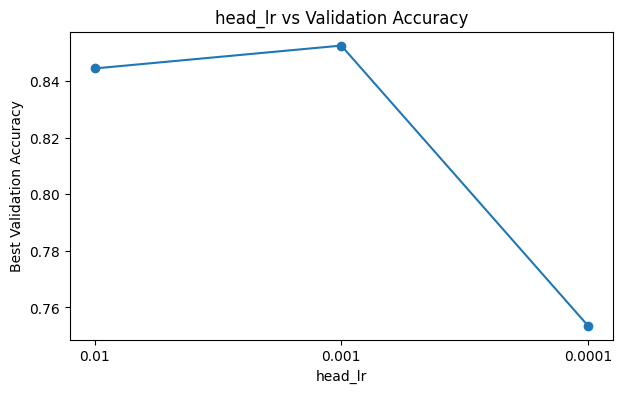

Selected head_lr = 0.001


In [ ]:
# EXPERIMENT 4 - HEAD LEARNING RATE
head_learning_rates = [0.01, 0.001, 0.0001]
head_lr_results = []

for lr in head_learning_rates:
    print("\n" + "=" * 60)
    print(f"Testing head learning rate: {lr}")
    print("=" * 60)

    tf.keras.utils.set_random_seed(SEED)
    model = build_mobilenet(learning_rate=lr, dropout_rate=0.3)
    scores = fit_and_score(model, train_ds, val_ds, TL_EXP_EPOCHS)
    scores["head_lr"] = lr
    head_lr_results.append(scores)

BEST["head_lr"] = pick_best(head_lr_results, "head_lr")

### 7.2 Dropout
The same three dropout values are tested on MobileNetV2, using the selected head learning rate.


Testing dropout: 0.2
Epoch 1/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 47s 531ms/step - accuracy: 0.5962 - loss: 1.0130 - val_accuracy: 0.7798 - val_loss: 0.5686
Epoch 2/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 446ms/step - accuracy: 0.7812 - loss: 0.5733 - val_accuracy: 0.8040 - val_loss: 0.4631
Epoch 3/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 32s 431ms/step - accuracy: 0.8081 - loss: 0.5064 - val_accuracy: 0.8222 - val_loss: 0.4326
Epoch 4/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 32s 427ms/step - accuracy: 0.8141 - loss: 0.4831 - val_accuracy: 0.8343 - val_loss: 0.4157
Epoch 5/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 32s 424ms/step - accuracy: 0.8367 - loss: 0.4456 - val_accuracy: 0.8444 - val_loss: 0.3998
Epoch 6/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 40s 418ms/step - accuracy: 0.8336 - loss: 0.4368 - val_accuracy: 0.8424 - val_loss: 0.3932

Testing dropout: 0.3
Epoch 1/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 48s 533ms/step - accuracy: 0.6027 - loss: 1.0095 - val_accuracy: 0.7980 - val_loss: 0.5196
Epoch 2/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 31s 418ms/step - accura

,Best Validation Accuracy,Best Validation Loss,Training Time (min),dropout,Selected
0,0.844444,0.393155,3.592587,0.2,False
1,0.856566,0.385502,3.561336,0.3,True
2,0.854545,0.408492,3.619160,0.5,False


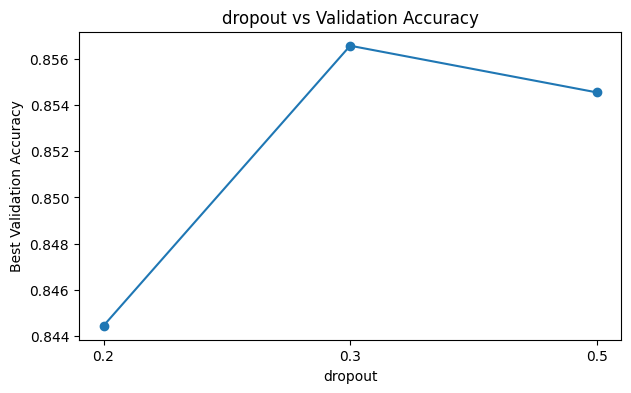

Selected dropout = 0.3


In [ ]:
# EXPERIMENT 5 - DROPOUT
dropout_rates = [0.2, 0.3, 0.5]
dropout_results = []

for dropout in dropout_rates:
    print("\n" + "=" * 60)
    print(f"Testing dropout: {dropout}")
    print("=" * 60)

    tf.keras.utils.set_random_seed(SEED)
    model = build_mobilenet(learning_rate=BEST["head_lr"], dropout_rate=dropout)
    scores = fit_and_score(model, train_ds, val_ds, TL_EXP_EPOCHS)
    scores["dropout"] = dropout
    dropout_results.append(scores)

BEST["dropout"] = pick_best(dropout_results, "dropout")

### 7.3 Batch size
Smaller batches give more frequent but noisier updates, which can sometimes help the model generalise. Larger batches give smoother updates but fewer of them in each epoch.


Testing batch size: 16
Epoch 1/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 50s 275ms/step - accuracy: 0.6183 - loss: 0.9429 - val_accuracy: 0.7980 - val_loss: 0.5136
Epoch 2/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 31s 214ms/step - accuracy: 0.7816 - loss: 0.5825 - val_accuracy: 0.8242 - val_loss: 0.4276
Epoch 3/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 42s 221ms/step - accuracy: 0.7955 - loss: 0.5209 - val_accuracy: 0.8404 - val_loss: 0.4192
Epoch 4/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 32s 216ms/step - accuracy: 0.8120 - loss: 0.4989 - val_accuracy: 0.8424 - val_loss: 0.4026
Epoch 5/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 32s 217ms/step - accuracy: 0.8193 - loss: 0.4547 - val_accuracy: 0.8505 - val_loss: 0.3906
Epoch 6/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 42s 226ms/step - accuracy: 0.8323 - loss: 0.4257 - val_accuracy: 0.8283 - val_loss: 0.4139

Testing batch size: 32
Epoch 1/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 49s 539ms/step - accuracy: 0.5897 - loss: 1.0288 - val_accuracy: 0.7818 - val_loss: 0.5475
Epoch 2/6
73/73 ━━━━━━━━━━━━━━━━━━━━ 31s 422

,Best Validation Accuracy,Best Validation Loss,Training Time (min),batch_size,Selected
0,0.850505,0.390580,3.819282,16,True
1,0.840404,0.401269,3.775967,32,False
2,0.822222,0.437228,4.043300,64,False


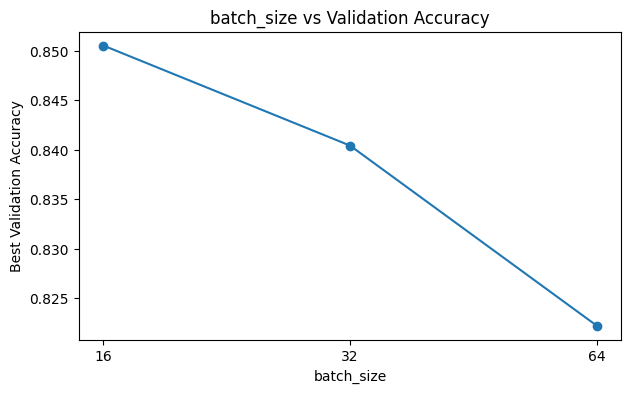

Selected batch_size = 16


In [ ]:
# EXPERIMENT 6 - BATCH SIZE
batch_sizes = [16, 32, 64]
batch_results = []

for batch_size in batch_sizes:
    print("\n" + "=" * 60)
    print(f"Testing batch size: {batch_size}")
    print("=" * 60)

    tf.keras.utils.set_random_seed(SEED)
    exp_train_ds = make_dataset(X_train, y_train, training=True, batch_size=batch_size)
    exp_val_ds = make_dataset(X_val, y_val, batch_size=batch_size)

    model = build_mobilenet(learning_rate=BEST["head_lr"], dropout_rate=BEST["dropout"])
    scores = fit_and_score(model, exp_train_ds, exp_val_ds, TL_EXP_EPOCHS)
    scores["batch_size"] = batch_size
    batch_results.append(scores)

BEST["batch_size"] = pick_best(batch_results, "batch_size")

# datasets with the selected batch size
best_train_ds = make_dataset(X_train, y_train, training=True, batch_size=BEST["batch_size"])
best_val_ds = make_dataset(X_val, y_val, batch_size=BEST["batch_size"])

### 7.4 Fine-tuning depth
This decides how much of the pretrained network is unfrozen during fine-tuning. Unfreezing only the top layers is safer, while unfreezing more gives the model more flexibility but increases the risk of overfitting.

For a fair comparison, one classification head is trained first with the selected settings and saved. Every option then starts from that same head. The fine-tuning learning rate is fixed at 0.00001 for this experiment.

In [ ]:
# TRAIN ONE SHARED HEAD (starting point for the fine-tuning experiments)
tf.keras.utils.set_random_seed(SEED)
head_model = build_mobilenet(learning_rate=BEST["head_lr"], dropout_rate=BEST["dropout"])
head_model.fit(
    best_train_ds,
    validation_data=best_val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=make_experiment_callbacks(),
    verbose=0
)

HEAD_WEIGHTS = str(MODEL_DIR / "shared_head.weights.h5")
head_model.save_weights(HEAD_WEIGHTS)
print("Shared head trained and saved.")


def build_from_head(fraction, finetune_lr):
    model = build_mobilenet(learning_rate=BEST["head_lr"], dropout_rate=BEST["dropout"])
    model.load_weights(HEAD_WEIGHTS)          # same starting point for every option
    unfreeze_top(model, fraction, finetune_lr)
    return model

Shared head trained and saved.



Testing fine-tuning depth: top 15%
Top 15% unfrozen: 16/154 layers trainable
Epoch 1/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 53s 289ms/step - accuracy: 0.8700 - loss: 0.3382 - val_accuracy: 0.8626 - val_loss: 0.3815
Epoch 2/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 31s 213ms/step - accuracy: 0.8731 - loss: 0.3338 - val_accuracy: 0.8626 - val_loss: 0.3921
Epoch 3/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 41s 214ms/step - accuracy: 0.8761 - loss: 0.3392 - val_accuracy: 0.8707 - val_loss: 0.3521
Epoch 4/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 33s 223ms/step - accuracy: 0.8752 - loss: 0.3234 - val_accuracy: 0.8646 - val_loss: 0.3470
Epoch 5/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 31s 215ms/step - accuracy: 0.8873 - loss: 0.2981 - val_accuracy: 0.8626 - val_loss: 0.3615
Epoch 6/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 32s 220ms/step - accuracy: 0.8860 - loss: 0.2950 - val_accuracy: 0.8707 - val_loss: 0.3406

Testing fine-tuning depth: top 30%
Top 30% unfrozen: 31/154 layers trainable
Epoch 1/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 56s 295ms/step - accuracy

,Best Validation Accuracy,Best Validation Loss,Training Time (min),unfreeze_frac,Selected
0,0.870707,0.340599,3.692643,0.15,False
1,0.888889,0.313334,3.764794,0.30,True
2,0.882828,0.304570,3.987818,0.50,False


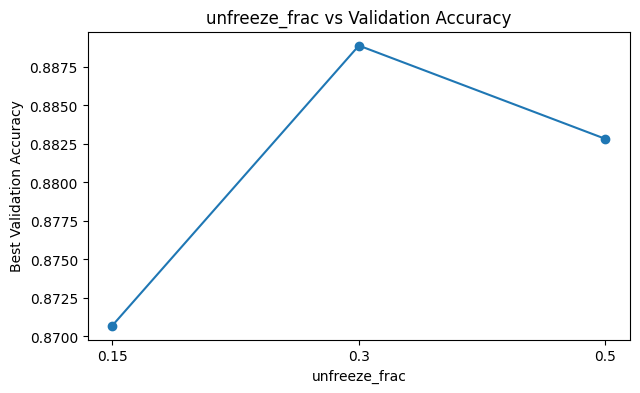

Selected unfreeze_frac = 0.3


In [ ]:
# EXPERIMENT 7 - FINE-TUNING DEPTH
unfreeze_fractions = [0.15, 0.30, 0.50]
depth_results = []

for fraction in unfreeze_fractions:
    print("\n" + "=" * 60)
    print(f"Testing fine-tuning depth: top {fraction:.0%}")
    print("=" * 60)

    tf.keras.utils.set_random_seed(SEED)
    model = build_from_head(fraction, finetune_lr=0.00001)
    scores = fit_and_score(model, best_train_ds, best_val_ds, TL_EXP_EPOCHS)
    scores["unfreeze_frac"] = fraction
    depth_results.append(scores)

BEST["unfreeze_frac"] = pick_best(depth_results, "unfreeze_frac")

### 7.5 Fine-tuning learning rate
The pretrained weights are already useful, so they only need small adjustments. A learning rate that is too high can overwrite what the network learned from ImageNet, while one that is too low barely changes anything.


Testing fine-tuning learning rate: 0.0001
Top 30% unfrozen: 31/154 layers trainable
Epoch 1/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 57s 310ms/step - accuracy: 0.7829 - loss: 0.5564 - val_accuracy: 0.8343 - val_loss: 0.4033
Epoch 2/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 32s 218ms/step - accuracy: 0.8440 - loss: 0.4159 - val_accuracy: 0.8646 - val_loss: 0.3538
Epoch 3/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 32s 221ms/step - accuracy: 0.8752 - loss: 0.3320 - val_accuracy: 0.8283 - val_loss: 0.5049
Epoch 4/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 42s 226ms/step - accuracy: 0.8969 - loss: 0.2796 - val_accuracy: 0.8929 - val_loss: 0.2894
Epoch 5/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 32s 221ms/step - accuracy: 0.8982 - loss: 0.2704 - val_accuracy: 0.8384 - val_loss: 0.3932
Epoch 6/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 41s 221ms/step - accuracy: 0.9099 - loss: 0.2305 - val_accuracy: 0.8909 - val_loss: 0.3242

Testing fine-tuning learning rate: 1e-05
Top 30% unfrozen: 31/154 layers trainable
Epoch 1/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 56s 304ms/st

,Best Validation Accuracy,Best Validation Loss,Training Time (min),finetune_lr,Selected
0,0.892929,0.289439,3.933371,0.000100,True
1,0.884848,0.322063,3.789968,0.000010,False
2,0.878788,0.350432,3.902461,0.000001,False


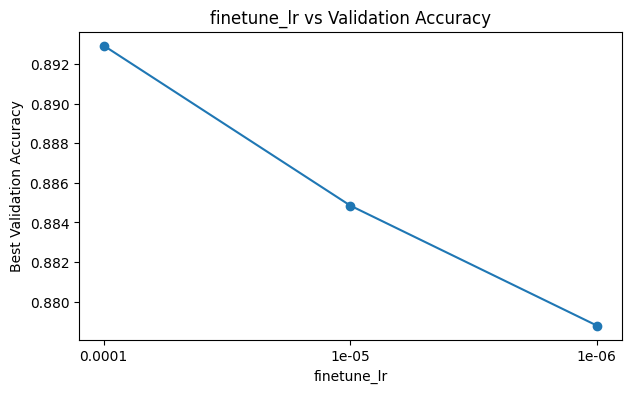

Selected finetune_lr = 0.0001


In [ ]:
# EXPERIMENT 8 - FINE-TUNING LEARNING RATE
finetune_learning_rates = [0.0001, 0.00001, 0.000001]
finetune_lr_results = []

for lr in finetune_learning_rates:
    print("\n" + "=" * 60)
    print(f"Testing fine-tuning learning rate: {lr}")
    print("=" * 60)

    tf.keras.utils.set_random_seed(SEED)
    model = build_from_head(BEST["unfreeze_frac"], finetune_lr=lr)
    scores = fit_and_score(model, best_train_ds, best_val_ds, TL_EXP_EPOCHS)
    scores["finetune_lr"] = lr
    finetune_lr_results.append(scores)

BEST["finetune_lr"] = pick_best(finetune_lr_results, "finetune_lr")

### 7.6 Tuning summary
This table combines the results of every experiment, with the selected value of each hyperparameter marked. It is also saved as a CSV file for the report.

In [ ]:
# TUNING SUMMARY
tuning_table = pd.concat(tuning_tables, ignore_index=True)
tuning_table = tuning_table[["Hyperparameter", "Value", "Best Validation Accuracy",
                             "Best Validation Loss", "Training Time (min)", "Selected"]]
tuning_table.to_csv(OUT_DIR / "hyperparameter_search.csv", index=False)

print("Selected hyperparameters:")
for name, value in BEST.items():
    print(f"  {name}: {value}")

display(tuning_table.round(4))

Selected hyperparameters:
  cnn_lr: 0.001
  cnn_dropout: 0.3
  head_lr: 0.001
  dropout: 0.3
  batch_size: 16
  unfreeze_frac: 0.3
  finetune_lr: 0.0001


,Hyperparameter,Value,Best Validation Accuracy,Best Validation Loss,Training Time (min),Selected
0,cnn_lr,0.0030,0.4101,1.3055,5.9496,False
1,cnn_lr,0.0010,0.4162,1.4591,5.5208,True
2,cnn_lr,0.0003,0.2182,2.0118,2.9494,False
3,cnn_dropout,0.2000,0.2222,2.5627,3.9594,False
4,cnn_dropout,0.3000,0.4889,1.2252,5.9097,True
5,cnn_dropout,0.5000,0.2222,2.7193,2.9173,False
6,head_lr,0.0100,0.8444,0.5049,2.4807,False
7,head_lr,0.0010,0.8525,0.3901,3.4657,True
8,head_lr,0.0001,0.7535,0.6655,3.7724,False
9,dropout,0.2000,0.8444,0.3932,3.5926,False


## 8. Model 2: MobileNetV2
MobileNetV2 (Sandler et al., 2018) was pretrained on ImageNet, so its layers can already detect general features such as edges, textures and everyday objects like beds, sinks and chairs, which are useful for recognising rooms (Yosinski et al., 2014). It was chosen because it is lightweight and designed for mobile and embedded devices. This suits HomeVision, where predictions need to run in real time on in-home cameras or a small local hub.

Training is done in two phases:
1. **Feature extraction:** the pretrained layers are frozen and only the new classification head is trained.
2. **Fine-tuning:** the top part of the network is unfrozen and trained with a small learning rate so it can adapt to indoor scenes. The lower layers stay frozen, since general features like edges do not need to change.

Batch normalisation layers stay frozen during fine-tuning. Their statistics were calculated on millions of images, and recalculating them from small batches of our data could make training unstable.

The function below runs both phases. It also saves a copy of the model after phase 1, so the feature extraction model can be tested separately and the gain from fine-tuning can be measured.

In [ ]:
# TWO-PHASE TRAINING FOR MOBILENETV2
HIST_KEYS = ["loss", "val_loss", "accuracy", "val_accuracy"]


def train_mobilenet(settings, name, keep_head_only=False):
    tf.keras.utils.set_random_seed(SEED)
    train_data = make_dataset(X_train, y_train, training=True, batch_size=settings["batch_size"])
    val_data = make_dataset(X_val, y_val, batch_size=settings["batch_size"])

    model = build_mobilenet(learning_rate=settings["head_lr"], dropout_rate=settings["dropout"])
    start = time.time()

    # Phase 1 - feature extraction
    print(f"Phase 1: feature extraction (lr={settings['head_lr']}, dropout={settings['dropout']}, "
          f"batch size={settings['batch_size']})")
    history_head = model.fit(
        train_data,
        validation_data=val_data,
        epochs=HEAD_EPOCHS,
        callbacks=make_callbacks()
    )
    head_time = time.time() - start

    # Save a copy of the phase 1 model
    if keep_head_only:
        head_name = name + "_head_only"
        model.save(MODEL_DIR / f"{head_name}.keras")
        trained_models[head_name] = tf.keras.models.load_model(MODEL_DIR / f"{head_name}.keras")
        histories[head_name] = {key: history_head.history[key] for key in HIST_KEYS}
        train_times[head_name] = head_time

    # Phase 2 - fine-tuning
    print(f"\nPhase 2: fine-tuning (top {settings['unfreeze_frac']:.0%}, lr={settings['finetune_lr']})")
    unfreeze_top(model, settings["unfreeze_frac"], settings["finetune_lr"])
    history_fine = model.fit(
        train_data,
        validation_data=val_data,
        epochs=FINETUNE_EPOCHS,
        callbacks=make_fine_tune_callbacks()
    )
    total_time = time.time() - start
    print(f"\n{name} training time: {total_time / 60:.2f} minutes")

    # Join the two phases into one history
    combined_history = {}
    for key in HIST_KEYS:
        combined_history[key] = history_head.history[key] + history_fine.history[key]

    model.save(MODEL_DIR / f"{name}.keras")
    histories[name] = combined_history
    train_times[name] = total_time
    trained_models[name] = model

    plot_history(combined_history, name, finetune_start=len(history_head.history["loss"]))
    return model

### 8.1 Train MobileNetV2 with the tuned settings

Phase 1: feature extraction (lr=0.001, dropout=0.3, batch size=16)
Epoch 1/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 50s 279ms/step - accuracy: 0.6274 - loss: 0.9402 - val_accuracy: 0.8020 - val_loss: 0.4972 - learning_rate: 0.0010
Epoch 2/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 32s 217ms/step - accuracy: 0.7773 - loss: 0.5713 - val_accuracy: 0.8222 - val_loss: 0.4500 - learning_rate: 0.0010
Epoch 3/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 32s 221ms/step - accuracy: 0.8024 - loss: 0.5102 - val_accuracy: 0.8424 - val_loss: 0.4071 - learning_rate: 0.0010
Epoch 4/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 42s 227ms/step - accuracy: 0.8089 - loss: 0.4877 - val_accuracy: 0.8485 - val_loss: 0.3953 - learning_rate: 0.0010
Epoch 5/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 40s 222ms/step - accuracy: 0.8241 - loss: 0.4549 - val_accuracy: 0.8465 - val_loss: 0.3962 - learning_rate: 0.0010
Epoch 6/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 31s 214ms/step - accuracy: 0.8336 - loss: 0.4342 - val_accuracy: 0.8505 - val_loss: 0.3858 - learning_rate: 0.0010
Epo

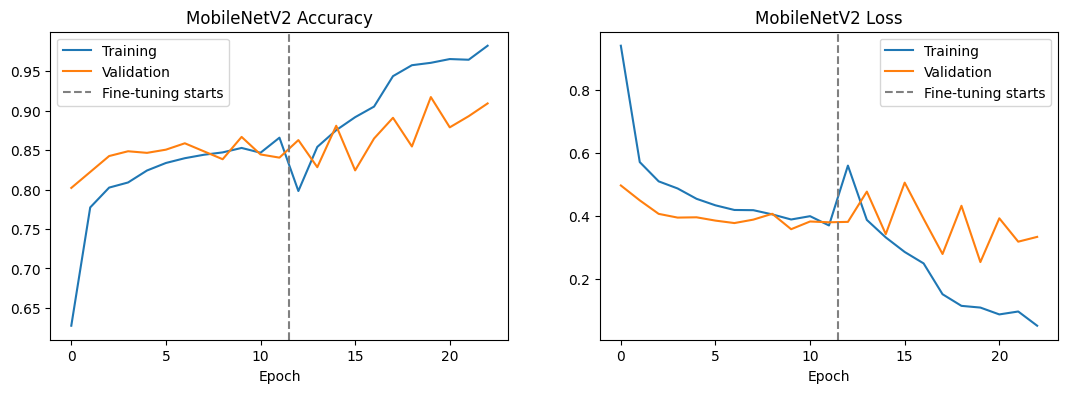

In [ ]:
# TRAIN MOBILENETV2 (TUNED)
tuned_settings = {
    "head_lr": BEST["head_lr"],
    "dropout": BEST["dropout"],
    "batch_size": BEST["batch_size"],
    "unfreeze_frac": BEST["unfreeze_frac"],
    "finetune_lr": BEST["finetune_lr"]
}

mobilenet = train_mobilenet(tuned_settings, "MobileNetV2", keep_head_only=True)

### 8.2 Baseline with default settings
To show whether the tuning was worth it, MobileNetV2 is also trained with common default settings instead of the tuned ones. These are the middle values from each experiment: a learning rate of 0.001, dropout of 0.3, batch size of 32, the top 30% unfrozen and a fine-tuning learning rate of 0.00001. Both versions are compared on the test set in section 10.

Phase 1: feature extraction (lr=0.001, dropout=0.3, batch size=32)
Epoch 1/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 49s 545ms/step - accuracy: 0.5966 - loss: 1.0062 - val_accuracy: 0.7838 - val_loss: 0.5469 - learning_rate: 0.0010
Epoch 2/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 31s 424ms/step - accuracy: 0.7652 - loss: 0.6267 - val_accuracy: 0.8343 - val_loss: 0.4375 - learning_rate: 0.0010
Epoch 3/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 444ms/step - accuracy: 0.7747 - loss: 0.5626 - val_accuracy: 0.8242 - val_loss: 0.4225 - learning_rate: 0.0010
Epoch 4/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 32s 428ms/step - accuracy: 0.7985 - loss: 0.5162 - val_accuracy: 0.8283 - val_loss: 0.4189 - learning_rate: 0.0010
Epoch 5/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 32s 427ms/step - accuracy: 0.8154 - loss: 0.4687 - val_accuracy: 0.8343 - val_loss: 0.4028 - learning_rate: 0.0010
Epoch 6/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 42s 437ms/step - accuracy: 0.8297 - loss: 0.4595 - val_accuracy: 0.8364 - val_loss: 0.4057 - learning_rate: 0.0010
Epoch 7/12
73/7

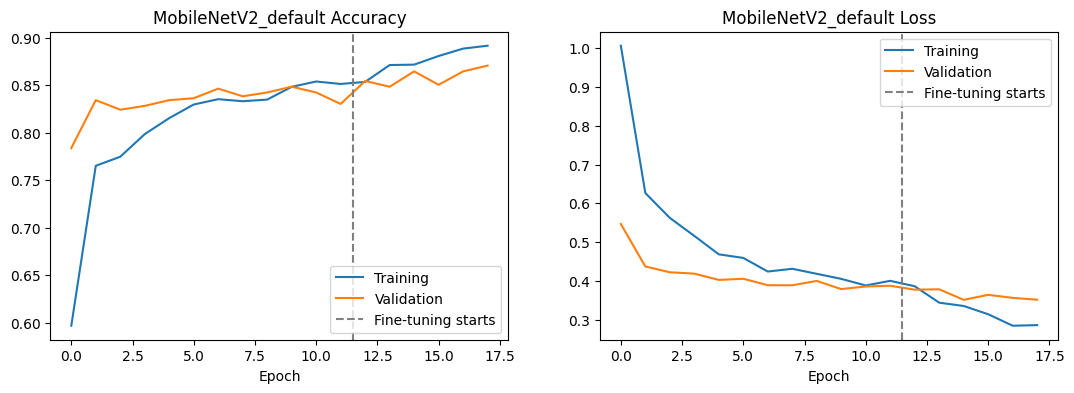

In [ ]:
# TRAIN MOBILENETV2 (DEFAULT SETTINGS)
default_settings = {
    "head_lr": 0.001,
    "dropout": 0.3,
    "batch_size": 32,
    "unfreeze_frac": 0.30,
    "finetune_lr": 0.00001
}

mobilenet_default = train_mobilenet(default_settings, "MobileNetV2_default")

## 9. Evaluation on the test set
Every model is evaluated on the same unseen test set. Along with accuracy, the following metrics are used:
- **Precision:** when the model predicts "kitchen", how often is it correct? Low precision would cause automations to trigger in the wrong room.
- **Recall:** out of all the real kitchens, how many did the model find? Low recall means automations would be missed.
- **F1-score:** a balance of precision and recall.

Macro averages are used so that each class counts equally, and macro F1 is the main metric for ranking the models.

In [ ]:
# TEST EVALUATION
def evaluate_model(model, name):
    probabilities = model.predict(test_ds, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    results[name] = {
        "probabilities": probabilities,
        "predictions": predictions,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, average="macro"),
        "recall": recall_score(y_test, predictions, average="macro"),
        "f1": f1_score(y_test, predictions, average="macro"),
        "report": classification_report(y_test, predictions, target_names=CLASSES, output_dict=True),
        "cm": confusion_matrix(y_test, predictions)
    }

    print("=" * 60)
    print(f"{name.upper()} CLASSIFICATION REPORT")
    print("=" * 60)
    print(classification_report(y_test, predictions, target_names=CLASSES, digits=3))


for name, model in trained_models.items():
    evaluate_model(model, name)

CUSTOMCNN CLASSIFICATION REPORT
                precision    recall  f1-score   support

airport_inside      0.895     0.837     0.865        92
           bar      0.835     0.789     0.811        90
       bedroom      0.623     0.768     0.688        99
       kitchen      0.728     0.761     0.744       109
    livingroom      0.591     0.495     0.539       105

      accuracy                          0.725       495
     macro avg      0.735     0.730     0.730       495
  weighted avg      0.729     0.725     0.724       495

MOBILENETV2_HEAD_ONLY CLASSIFICATION REPORT
                precision    recall  f1-score   support

airport_inside      0.946     0.957     0.951        92
           bar      0.938     0.833     0.882        90
       bedroom      0.825     0.859     0.842        99
       kitchen      0.839     0.908     0.872       109
    livingroom      0.752     0.724     0.738       105

      accuracy                          0.855       495
     macro avg      0.8

### 9.1 Confusion matrices
The confusion matrices show which rooms are classified correctly (the diagonal) and which rooms are mixed up with each other.

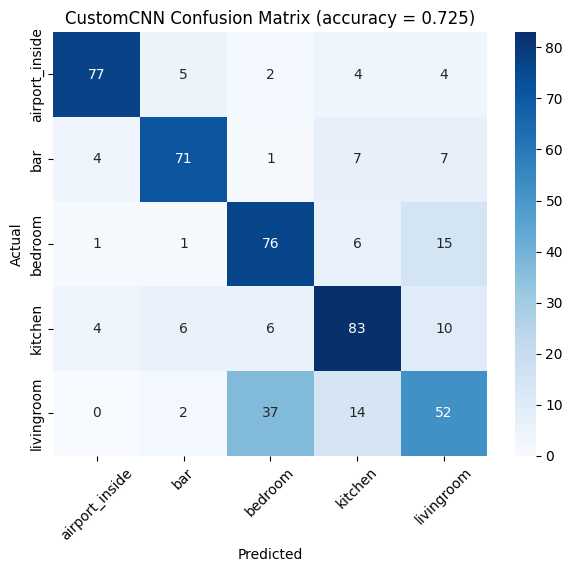

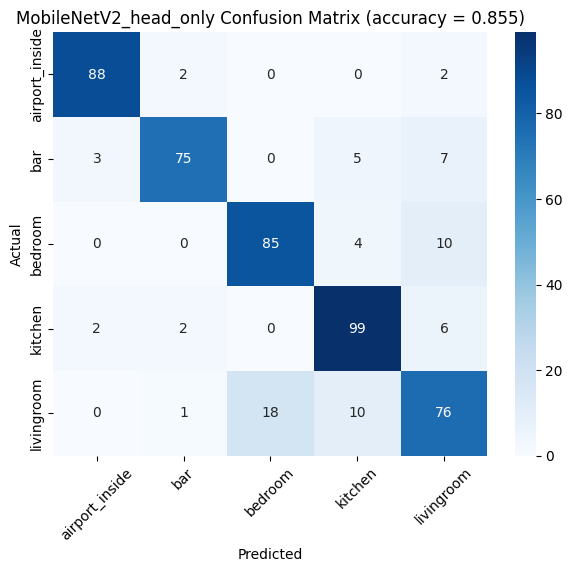

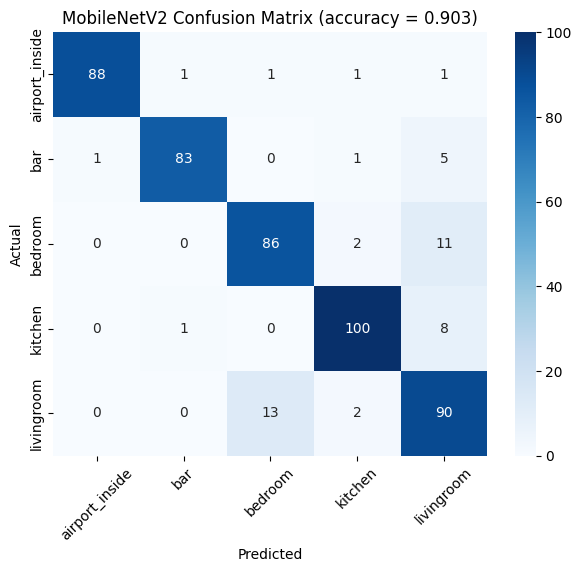

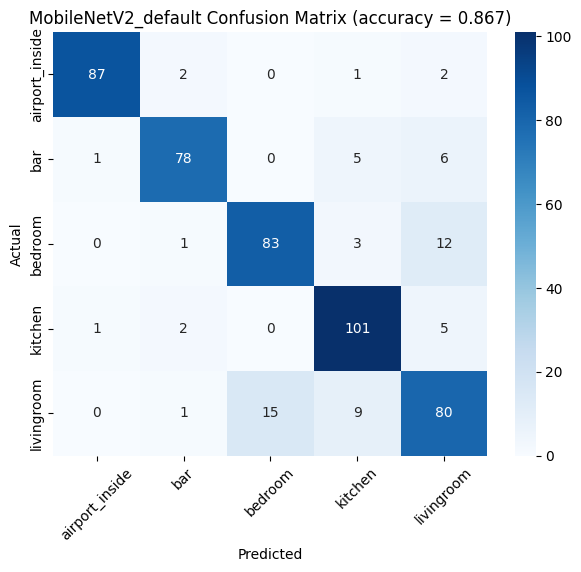

In [ ]:
# CONFUSION MATRICES
for name in results:
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(
        results[name]["cm"],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES
    )
    plt.title(f"{name} Confusion Matrix (accuracy = {results[name]['accuracy']:.3f})")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.xticks(rotation=45)
    plt.savefig(FIG_DIR / f"confusion_matrix_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

### 9.2 Class-wise F1-score
This chart compares the F1-score of each class across the models, which makes it easy to see which rooms are the hardest to recognise.

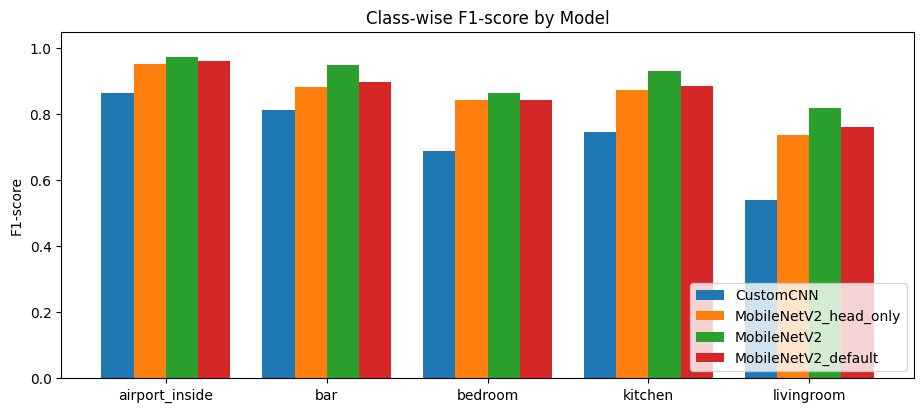

,CustomCNN,MobileNetV2_head_only,MobileNetV2,MobileNetV2_default
airport_inside,0.865,0.951,0.972,0.961
bar,0.811,0.882,0.949,0.897
bedroom,0.688,0.842,0.864,0.843
kitchen,0.744,0.872,0.930,0.886
livingroom,0.539,0.738,0.818,0.762


In [ ]:
# CLASS-WISE F1-SCORE
classwise_f1 = pd.DataFrame(index=CLASSES)
for name in results:
    classwise_f1[name] = [results[name]["report"][cls]["f1-score"] for cls in CLASSES]

classwise_f1.plot(kind="bar", figsize=(11, 4.5), width=0.8)
plt.title("Class-wise F1-score by Model")
plt.ylabel("F1-score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.savefig(FIG_DIR / "classwise_f1.png", dpi=150, bbox_inches="tight")
plt.show()

display(classwise_f1.round(3))

## 10. Model comparison
HomeVision needs to make predictions in real time, so accuracy is not the only thing that matters. This table compares each model on its test metrics, number of parameters, file size, training time and the time it takes to classify a single image (one frame at a time, the same way a live camera would send them).

In [ ]:
# MODEL COMPARISON TABLE
def measure_latency_ms(model, runs=50):
    image = tf.convert_to_tensor(X_test[:1].astype("float32"))
    for _ in range(5):                 # warm-up runs are not timed
        model(image, training=False)
    start = time.perf_counter()
    for _ in range(runs):
        model(image, training=False)
    return (time.perf_counter() - start) / runs * 1000


rows = []
for name, model in trained_models.items():
    rows.append({
        "Model": name,
        "Test Accuracy": results[name]["accuracy"],
        "Macro Precision": results[name]["precision"],
        "Macro Recall": results[name]["recall"],
        "Macro F1": results[name]["f1"],
        "Parameters (M)": model.count_params() / 1e6,
        "File Size (MB)": (MODEL_DIR / f"{name}.keras").stat().st_size / 1e6,
        "Latency (ms)": measure_latency_ms(model),
        "Training Time (min)": train_times[name] / 60,
        "Epochs Run": len(histories[name]["loss"])
    })

comparison = pd.DataFrame(rows).set_index("Model").sort_values("Macro F1", ascending=False)
comparison.to_csv(OUT_DIR / "model_comparison.csv")
display(comparison.round(3))

,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Parameters (M),File Size (MB),Latency (ms),Training Time (min),Epochs Run
Model,,,,,,,,,
MobileNetV2,0.903,0.910,0.904,0.907,2.264,23.944,163.491,14.038,23
MobileNetV2_default,0.867,0.873,0.868,0.870,2.264,23.944,149.242,11.217,18
MobileNetV2_head_only,0.855,0.860,0.856,0.857,2.264,9.700,162.973,7.275,12
CustomCNN,0.725,0.735,0.730,0.730,1.210,14.625,30.549,26.235,40


### 10.1 Performance gains
This cell measures the effect of each main decision on test accuracy and macro F1:
- **Transfer learning:** MobileNetV2 compared with the custom CNN.
- **Fine-tuning:** MobileNetV2 after phase 2 compared with phase 1 only.
- **Hyperparameter tuning:** tuned MobileNetV2 compared with the default settings.

In [ ]:
# PERFORMANCE GAINS
def gain(model_a, model_b):
    accuracy_gain = (results[model_a]["accuracy"] - results[model_b]["accuracy"]) * 100
    f1_gain = (results[model_a]["f1"] - results[model_b]["f1"]) * 100
    return round(accuracy_gain, 2), round(f1_gain, 2)


gains = pd.DataFrame({
    "Comparison": [
        "Transfer learning (MobileNetV2 vs Custom CNN)",
        "Fine-tuning (MobileNetV2 vs head only)",
        "Hyperparameter tuning (tuned vs default)"
    ],
    "Accuracy Gain (pts)": [
        gain("MobileNetV2", "CustomCNN")[0],
        gain("MobileNetV2", "MobileNetV2_head_only")[0],
        gain("MobileNetV2", "MobileNetV2_default")[0]
    ],
    "Macro F1 Gain (pts)": [
        gain("MobileNetV2", "CustomCNN")[1],
        gain("MobileNetV2", "MobileNetV2_head_only")[1],
        gain("MobileNetV2", "MobileNetV2_default")[1]
    ]
})
display(gains)

,Comparison,Accuracy Gain (pts),Macro F1 Gain (pts)
0,Transfer learning (MobileNetV2 vs Custom CNN),17.78,17.72
1,Fine-tuning (MobileNetV2 vs head only),4.85,4.97
2,Hyperparameter tuning (tuned vs default),3.64,3.71


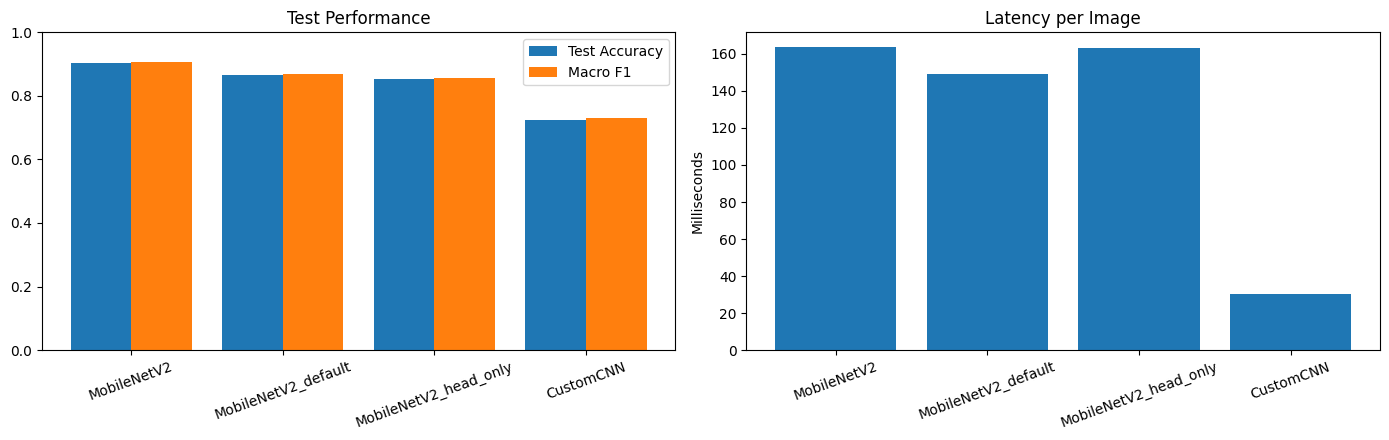

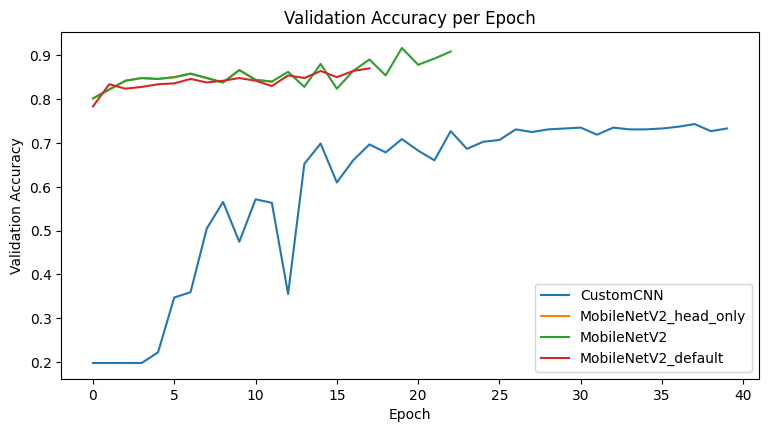

In [ ]:
# COMPARISON CHARTS
plt.figure(figsize=(14, 4.5))

plt.subplot(1, 2, 1)
x = np.arange(len(comparison))
plt.bar(x - 0.2, comparison["Test Accuracy"], width=0.4, label="Test Accuracy")
plt.bar(x + 0.2, comparison["Macro F1"], width=0.4, label="Macro F1")
plt.xticks(x, comparison.index, rotation=20)
plt.ylim(0, 1)
plt.title("Test Performance")
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(comparison.index, comparison["Latency (ms)"])
plt.xticks(rotation=20)
plt.title("Latency per Image")
plt.ylabel("Milliseconds")

plt.tight_layout()
plt.savefig(FIG_DIR / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Validation accuracy of every model
plt.figure(figsize=(9, 4.5))
for name, history in histories.items():
    plt.plot(history["val_accuracy"], label=name)
plt.title("Validation Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.savefig(FIG_DIR / "val_accuracy_all.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Error analysis and explainability
### 11.1 Common mistakes
This section looks at the final tuned MobileNetV2 model. It lists the class pairs that are confused most often and shows the wrong predictions the model was most confident about. This helps identify which automation rules would be most at risk, for example kitchen lighting turning on in a bar.

Most common mistakes (actual -> predicted):
  livingroom      -> bedroom        : 13
  bedroom         -> livingroom     : 11
  kitchen         -> livingroom     : 8
  bar             -> livingroom     : 5
  livingroom      -> kitchen        : 2


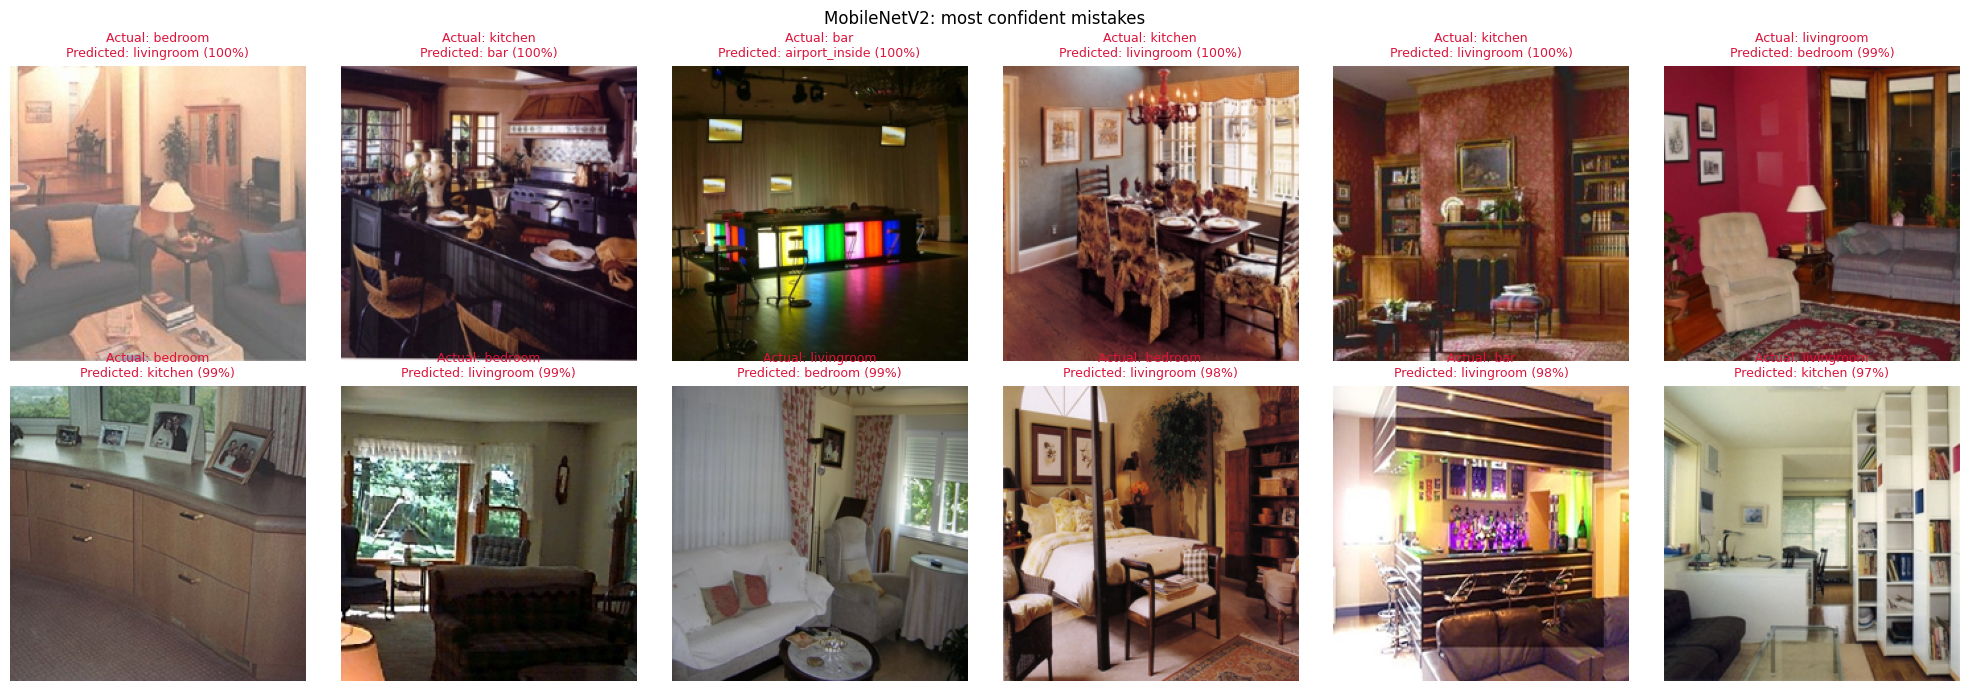

In [ ]:
# TOP CONFUSIONS AND MISCLASSIFIED IMAGES
FINAL_MODEL = "MobileNetV2"
final_results = results[FINAL_MODEL]

# Most common mistakes (off-diagonal values of the confusion matrix)
confusions = []
cm = final_results["cm"]
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i, j] > 0:
            confusions.append((cm[i, j], CLASSES[i], CLASSES[j]))
confusions.sort(reverse=True)

print("Most common mistakes (actual -> predicted):")
for count, actual, predicted in confusions[:5]:
    print(f"  {actual:15s} -> {predicted:15s}: {count}")

# Wrong predictions, most confident first
predictions = final_results["predictions"]
confidence = final_results["probabilities"].max(axis=1)
wrong = np.where(predictions != y_test)[0]
wrong = wrong[np.argsort(-confidence[wrong])][:12]

plt.figure(figsize=(20, 7))
for plot_index, i in enumerate(wrong):
    plt.subplot(2, 6, plot_index + 1)
    plt.imshow(X_test[i])
    plt.title(f"Actual: {CLASSES[y_test[i]]}\nPredicted: {CLASSES[predictions[i]]} ({confidence[i]:.0%})",
              fontsize=9, color="crimson")
    plt.axis("off")
plt.suptitle(f"{FINAL_MODEL}: most confident mistakes")
plt.tight_layout()
plt.savefig(FIG_DIR / "misclassified.png", dpi=150, bbox_inches="tight")
plt.show()

### 11.2 Grad-CAM
Grad-CAM highlights the parts of an image that had the most influence on a prediction. It is used here to check whether the model is looking at sensible things, such as a bed or a stove, rather than unrelated details like a window or a watermark. This matters for trust, and it also helps explain why some mistakes happen.

It works by taking the gradient of the predicted class score with respect to the last convolutional feature maps. Each feature map is weighted by its average gradient, and the weighted maps are added together to produce a heatmap.

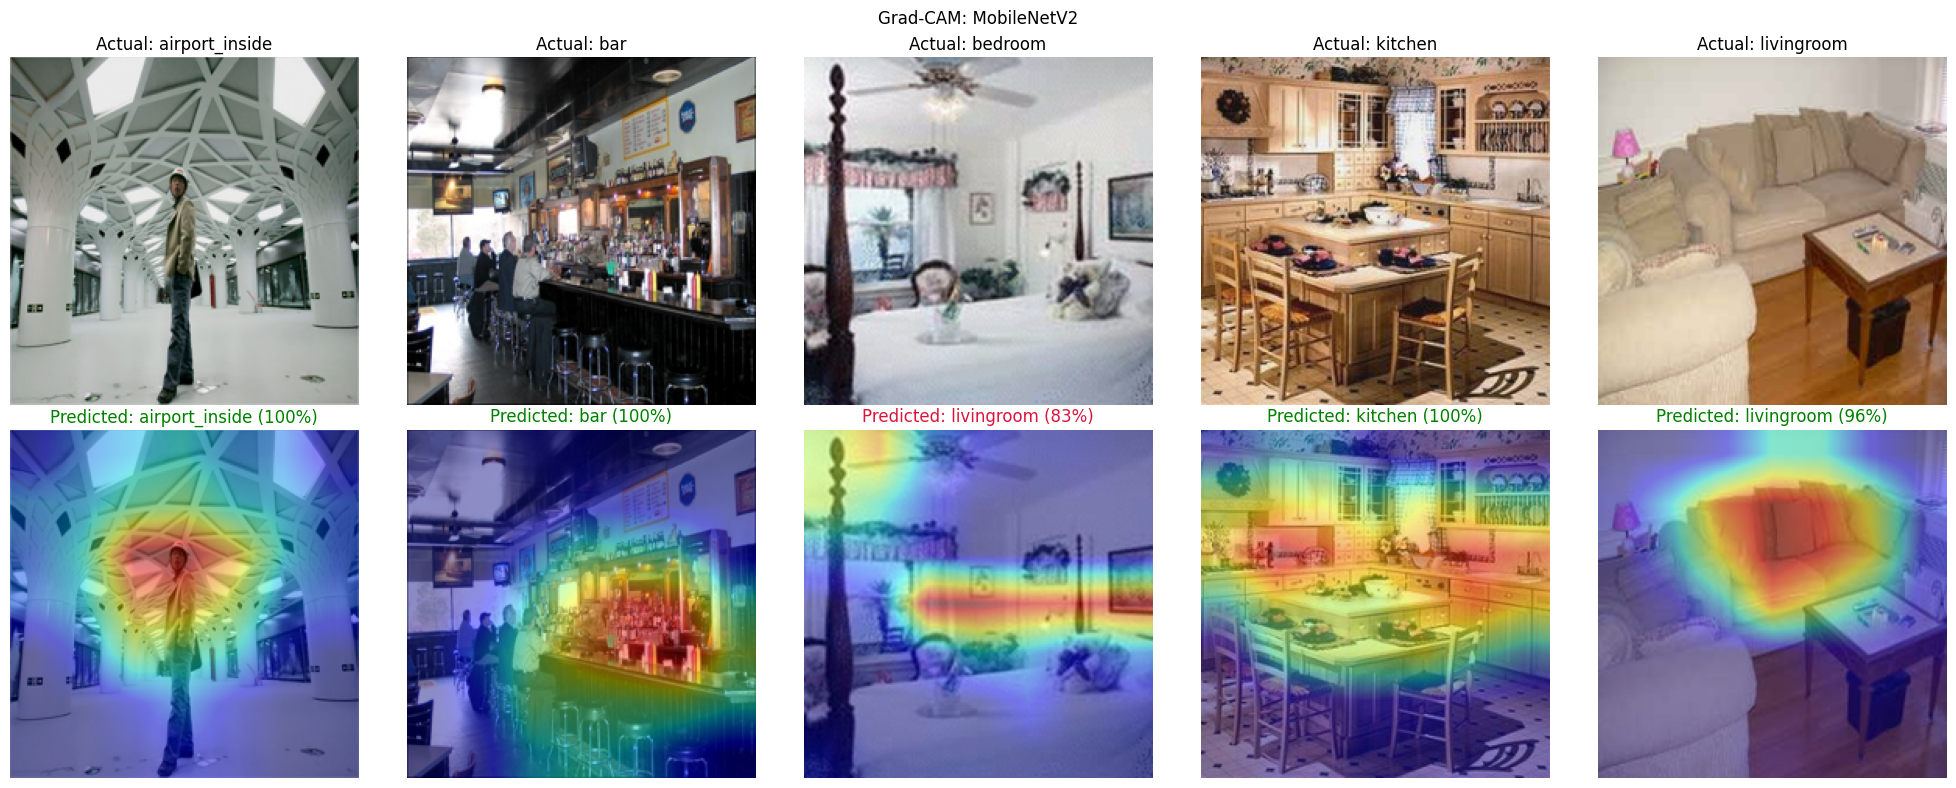

In [ ]:
# GRAD-CAM
def grad_cam(model, image):
    base_model = get_base_model(model)
    image = tf.convert_to_tensor(image[np.newaxis].astype("float32"))

    with tf.GradientTape() as tape:
        x = model.get_layer("preprocess")(image)
        feature_maps = base_model(x, training=False)     # last convolutional output
        tape.watch(feature_maps)
        x = model.get_layer("gap")(feature_maps)
        predictions = model.get_layer("predictions")(x)
        class_index = int(tf.argmax(predictions[0]))
        class_score = predictions[0, class_index]

    gradients = tape.gradient(class_score, feature_maps)
    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))          # importance of each feature map

    heatmap = tf.reduce_sum(feature_maps[0] * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)   # keep positive values, scale to 0-1
    heatmap = tf.image.resize(heatmap[..., np.newaxis], (IMG_SIZE, IMG_SIZE))[..., 0]

    return heatmap.numpy(), class_index, float(class_score)


# One random test image from each class
rng = np.random.default_rng(SEED)
plt.figure(figsize=(4 * NUM_CLASSES, 8))

for col in range(NUM_CLASSES):
    i = rng.choice(np.where(y_test == col)[0])
    heatmap, predicted, score = grad_cam(trained_models[FINAL_MODEL], X_test[i])

    plt.subplot(2, NUM_CLASSES, col + 1)
    plt.imshow(X_test[i])
    plt.title(f"Actual: {CLASSES[y_test[i]]}")
    plt.axis("off")

    plt.subplot(2, NUM_CLASSES, NUM_CLASSES + col + 1)
    plt.imshow(X_test[i])
    plt.imshow(heatmap, cmap="jet", alpha=0.45)
    colour = "green" if predicted == y_test[i] else "crimson"
    plt.title(f"Predicted: {CLASSES[predicted]} ({score:.0%})", color=colour)
    plt.axis("off")

plt.suptitle(f"Grad-CAM: {FINAL_MODEL}")
plt.tight_layout()
plt.savefig(FIG_DIR / "gradcam.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Applications, privacy and limitations
### 12.1 Practical applications and automation benefits
Once the room type is known, HomeVision can adjust the environment without anyone having to set it up manually:

| Room | Example automations |
|---|---|
| Bedroom | warm, dimmed lighting at night, quieter HVAC settings, privacy mode for cameras |
| Kitchen | bright task lighting, extractor fan control, smoke and heat alerts |
| Living room | lighting scenes for watching TV, occupancy-based heating and cooling |
| Bar | ambience lighting schedules, energy saving outside opening hours |
| Airport (inside) | lighting and HVAC zones based on crowd levels, support for surveillance staff |

The main benefits are energy savings, since lighting and HVAC only run as needed for each space, more comfort for residents, and less manual setup for building managers. Because MobileNetV2 is small and fast, it could run directly on the camera or a local hub instead of sending images to the cloud.

### 12.2 Privacy and ethical concerns
- **Cameras in private spaces.** Bedrooms and living rooms are very private areas. Images should be processed on the device and deleted straight away, and only the predicted room label should be kept. This is one of the main reasons a lightweight model like MobileNetV2 was chosen.
- **Consent and transparency.** Residents and visitors should know when a camera is active, and there should be a simple way to switch it off. In Sri Lanka, the Personal Data Protection Act No. 9 of 2022 sets out rules for how personal data like this must be handled.
- **Dataset bias.** The MIT Indoor dataset is mostly made up of images collected from the internet, many of them from Western homes and buildings. Sri Lankan homes may look different in layout and decoration, so the model could perform worse in practice than the test results suggest.
- **Surveillance misuse.** A system designed for automation could be repurposed to monitor people. Access to the camera feeds should be limited and logged.
- **Wrong predictions.** A misclassification should only lead to low-risk actions, such as the wrong lighting. Safety-related actions, such as gas or fire alerts, should not depend on this model alone.

### 12.3 Limitations and future improvements
- Only five classes were used. A real product would need many more room types.
- The dataset is fairly small, and each class has only a few hundred images.
- The hyperparameters were tuned one at a time with short runs, so combinations that work well together may have been missed.
- Each result comes from a single run with one random seed. Repeating the runs with different seeds, or using cross-validation, would show how stable the results are.
- The latency was measured on a Colab GPU, not on the type of device HomeVision would use.

Future work could include collecting images from Sri Lankan homes, converting the model to TensorFlow Lite with quantisation and testing it on an edge device such as a Raspberry Pi, trying other efficient backbones, and adding more room classes.

## 13. Implementation report
This cell collects the key numbers from this run and saves them to a JSON file, so they can be copied into the written report.

In [ ]:
# SUMMARY OF THIS RUN
final = comparison.loc[FINAL_MODEL]
cnn = comparison.loc["CustomCNN"]

weakest_class = min(CLASSES, key=lambda cls: final_results["report"][cls]["f1-score"])
if confusions:
    top_confusion = f"{confusions[0][1]} -> {confusions[0][2]} ({confusions[0][0]})"
else:
    top_confusion = "none"

summary = {
    "final_model": FINAL_MODEL,
    "final_test_accuracy": round(float(final["Test Accuracy"]), 4),
    "final_macro_f1": round(float(final["Macro F1"]), 4),
    "custom_cnn_test_accuracy": round(float(cnn["Test Accuracy"]), 4),
    "transfer_learning_gain_pts": gain("MobileNetV2", "CustomCNN")[0],
    "fine_tuning_gain_pts": gain("MobileNetV2", "MobileNetV2_head_only")[0],
    "tuning_gain_pts": gain("MobileNetV2", "MobileNetV2_default")[0],
    "selected_hyperparameters": BEST,
    "weakest_class": weakest_class,
    "most_common_mistake": top_confusion,
    "images_used": int(len(X_all)),
    "files_rejected": int(len(rejected))
}

with open(OUT_DIR / "run_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

pd.Series(summary, name="Value").to_frame()

,Value
final_model,MobileNetV2
final_test_accuracy,0.903
final_macro_f1,0.9067
custom_cnn_test_accuracy,0.7253
transfer_learning_gain_pts,17.78
fine_tuning_gain_pts,4.85
tuning_gain_pts,3.64
selected_hyperparameters,"{'cnn_lr': 0.001, 'cnn_dropout': 0.3, 'head_lr..."
weakest_class,livingroom
most_common_mistake,livingroom -> bedroom (13)


### Design decisions
- **Data:** five classes covering both home and building settings, including some visually similar pairs. Corrupt and duplicate images were removed, all images were converted to RGB and resized to 224×224, labels were encoded as integers, and the data was split 70/15/15 with stratification.
- **Augmentation:** flips, small rotations, zoom, shifts, brightness and contrast, chosen to match the lighting, camera angle and layout problems in the brief. Its effect was tested directly in section 6.4.
- **Models:** a custom CNN trained from scratch as a baseline, and MobileNetV2 trained with transfer learning in two phases (feature extraction, then fine-tuning with batch normalisation frozen).
- **Training:** the Adam optimiser with sparse categorical cross-entropy loss. EarlyStopping and ReduceLROnPlateau were used in the final runs.
- **Hyperparameters:** two tuned for the CNN (learning rate, dropout) and five for MobileNetV2 (head learning rate, dropout, batch size, fine-tuning depth, fine-tuning learning rate), with three values each. All were selected using validation accuracy only.
- **Evaluation:** accuracy, macro precision, recall and F1, confusion matrices, class-wise F1, latency and model size, plus Grad-CAM for explainability.

